## ECG External Validation using Unseen Record 119

1. Installing Libraries

In [ ]:
!pip install wfdb -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.0 MB/s eta 0:00:00


2. Importing Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import pywt
import joblib
from scipy.stats import skew, kurtosis
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

3. Sampling Frequency, Segment Duration & Samples per segment

In [ ]:
fs = 360
segment_duration = 5
segment_length = fs * segment_duration
print("Sampling frequency:", fs, "Hz")
print("Segment duration:", segment_duration, "seconds")
print("Samples per segment:", segment_length)

Sampling frequency: 360 Hz
Segment duration: 5 seconds
Samples per segment: 1800


4. Loading Unseen Clean ECG Record 119

In [ ]:
record_119 = wfdb.rdrecord("119", pn_dir="mitdb")
print("Record 119 loaded successfully.")
print("Sampling frequency:", record_119.fs)
print("Signal shape:", record_119.p_signal.shape)
print("Signal names:", record_119.sig_name)

Record 119 loaded successfully.
Sampling frequency: 360
Signal shape: (650000, 2)
Signal names: ['MLII', 'V1']


5. Extracting ECG Signal

In [ ]:
ecg_119 = record_119.p_signal[:, 0]
print("Record 119 ECG samples:", len(ecg_119))
print("Minimum:", np.min(ecg_119))
print("Maximum:", np.max(ecg_119))

Record 119 ECG samples: 650000
Minimum: -2.985
Maximum: 2.5


6. Loading Noise Signals

In [ ]:
bw_record = wfdb.rdrecord("bw", pn_dir="nstdb")
ma_record = wfdb.rdrecord("ma", pn_dir="nstdb")
em_record = wfdb.rdrecord("em", pn_dir="nstdb")
bw_119 = bw_record.p_signal[:, 0]
ma_119 = ma_record.p_signal[:, 0]
em_119 = em_record.p_signal[:, 0]
print("BW samples:", len(bw_119))
print("MA samples:", len(ma_119))
print("EM samples:", len(em_119))

BW samples: 650000
MA samples: 650000
EM samples: 650000


7. Checking Sampling Frequencies

In [ ]:
print("Record 119 sampling frequency:", record_119.fs)
print("BW sampling frequency:", bw_record.fs)
print("MA sampling frequency:", ma_record.fs)
print("EM sampling frequency:", em_record.fs)

Record 119 sampling frequency: 360
BW sampling frequency: 360
MA sampling frequency: 360
EM sampling frequency: 360


8. Visualizing unseen ECG

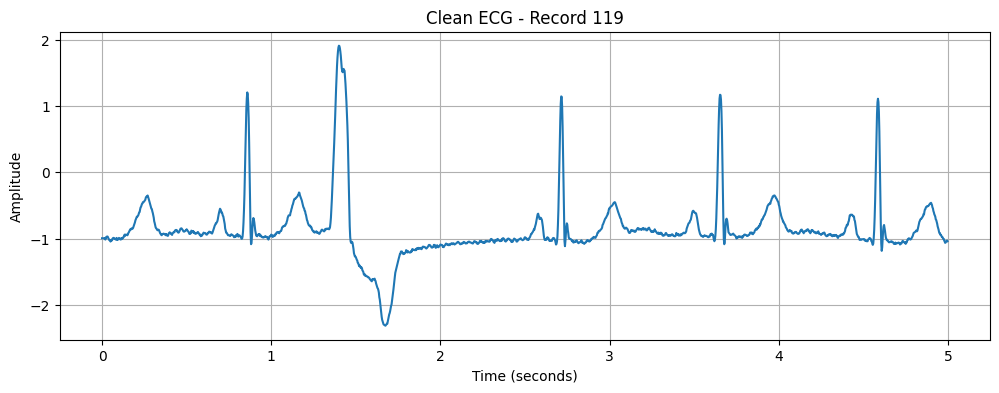

In [ ]:
time = np.arange(0, 5, 1/fs)
plt.figure(figsize=(12, 4))
plt.plot(time, ecg_119[:segment_length])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Clean ECG - Record 119")
plt.grid()
plt.show()

9. Preprocessing Record 119


In [ ]:
def preprocess_signal(signal_data):
    signal_data = np.asarray(signal_data, dtype=float)
    signal_data = signal_data - np.mean(signal_data)
    std = np.std(signal_data)
    if std != 0:
        signal_data = signal_data / std
    return signal_data

In [ ]:
ecg_119_processed = preprocess_signal(ecg_119)
bw_119_processed = preprocess_signal(bw_119)
ma_119_processed = preprocess_signal(ma_119)
em_119_processed = preprocess_signal(em_119)

In [ ]:
print("ECG mean:", np.mean(ecg_119_processed))
print("ECG standard deviation:", np.std(ecg_119_processed))
print("BW mean:", np.mean(bw_119_processed))
print("BW standard deviation:", np.std(bw_119_processed))
print("MA mean:", np.mean(ma_119_processed))
print("MA standard deviation:", np.std(ma_119_processed))
print("EM mean:", np.mean(em_119_processed))
print("EM standard deviation:", np.std(em_119_processed))
print("\nProcessed Signal Length:")
print("ECG:", len(ecg_119_processed))
print("BW:", len(bw_119_processed))
print("MA:", len(ma_119_processed))
print("EM:", len(em_119_processed))

ECG mean: 3.1517489472977245e-16
ECG standard deviation: 0.9999999999999997
BW mean: -7.695724399617086e-18
BW standard deviation: 1.0000000000000002
MA mean: 1.8452248276354602e-17
MA standard deviation: 0.9999999999999999
EM mean: -1.1281232358529591e-17
EM standard deviation: 0.9999999999999997

Processed Signal Length:
ECG: 650000
BW: 650000
MA: 650000
EM: 650000


10. Signal Segmentation

In [ ]:
fs = int(record_119.fs)
segment_duration = 5  # seconds
segment_length = fs * segment_duration
print("Sampling frequency:", fs)
print("Segment duration:", segment_duration, "seconds")
print("Samples per segment:", segment_length)

Sampling frequency: 360
Segment duration: 5 seconds
Samples per segment: 1800


In [ ]:
def create_segments(signal_data, segment_length):
    segments = []
    number_of_segments = len(signal_data) // segment_length
    for i in range(number_of_segments):
        start = i * segment_length
        end = start + segment_length
        segment = signal_data[start:end]
        segments.append(segment)
    return np.array(segments)

In [ ]:
ecg_segments_119 = create_segments(ecg_119_processed, segment_length)
bw_segments_119 = create_segments(bw_119_processed, segment_length)
ma_segments_119 = create_segments(ma_119_processed, segment_length)
em_segments_119 = create_segments(em_119_processed, segment_length)

In [ ]:
print("ECG segments:", ecg_segments_119.shape)
print("BW segments:", bw_segments_119.shape)
print("MA segments:", ma_segments_119.shape)
print("EM segments:", em_segments_119.shape)

ECG segments: (361, 1800)
BW segments: (361, 1800)
MA segments: (361, 1800)
EM segments: (361, 1800)


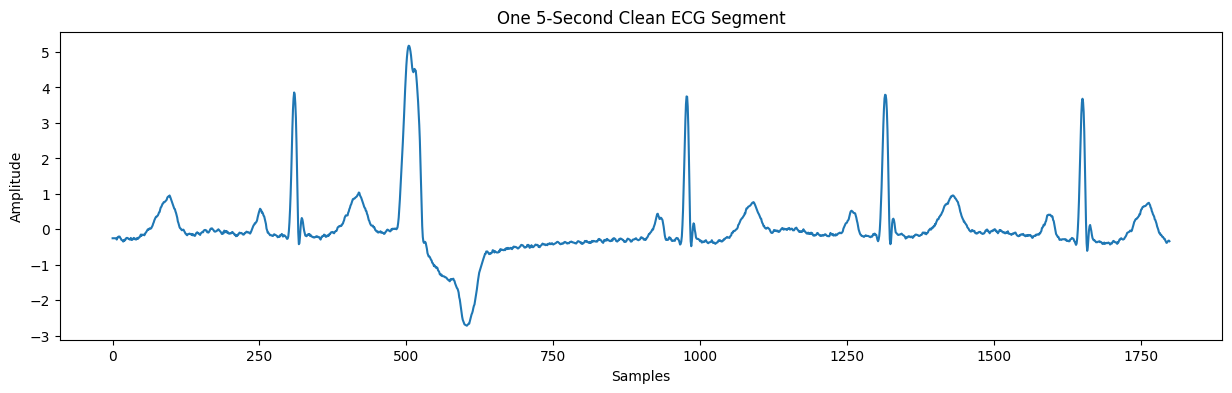

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(ecg_segments_119[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Clean ECG Segment")
plt.show()

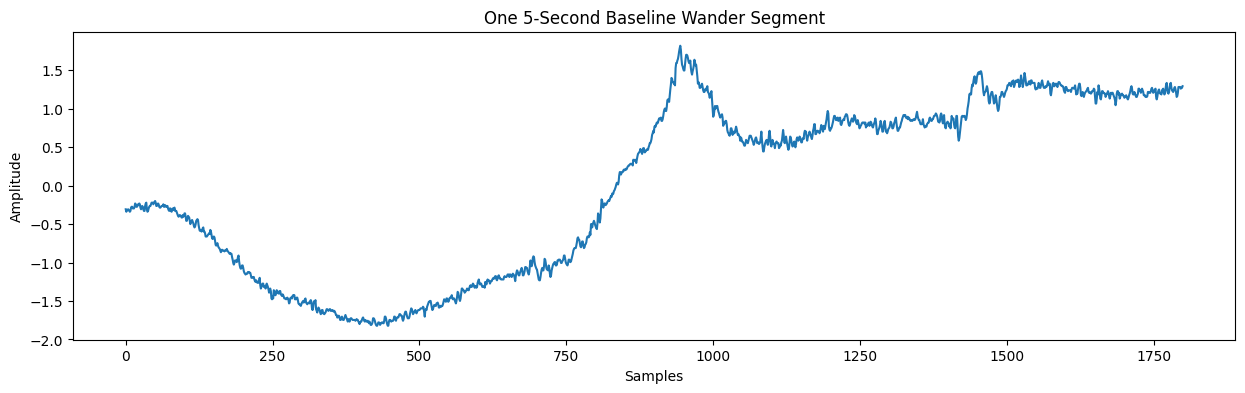

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(bw_segments_119[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Baseline Wander Segment")
plt.show()

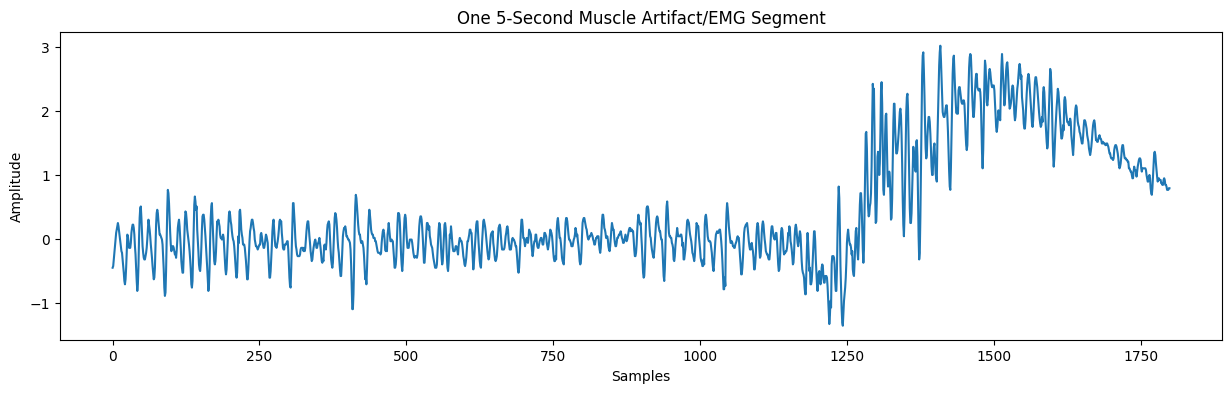

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(ma_segments_119[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Muscle Artifact/EMG Segment")
plt.show()

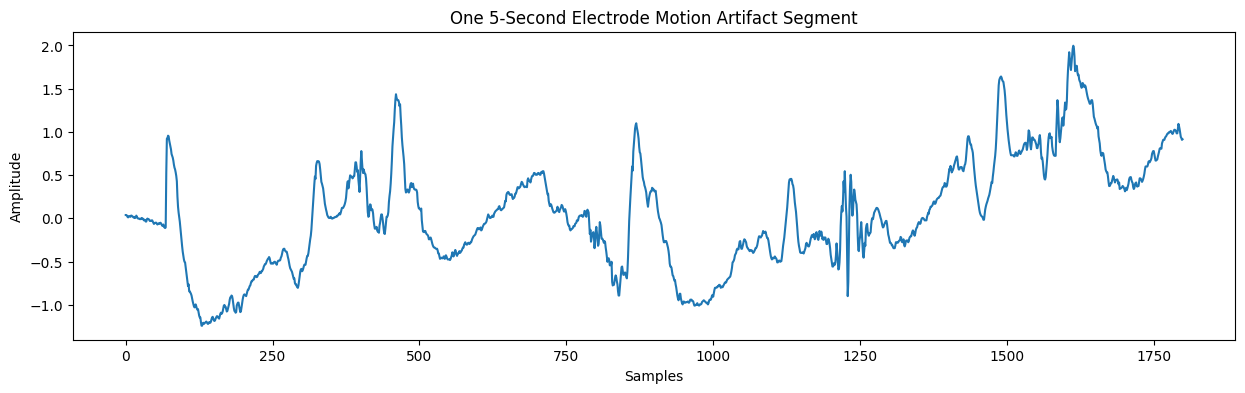

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(em_segments_119[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Electrode Motion Artifact Segment")
plt.show()

11. SNR Noise Function

In [ ]:
def add_noise_snr(clean_signal, noise_signal, snr_db):
    noise_signal = noise_signal[:len(clean_signal)]
    noise_signal = noise_signal - np.mean(noise_signal)
    signal_power = np.mean(clean_signal ** 2)
    noise_power = np.mean(noise_signal ** 2)
    desired_noise_power = signal_power / (10 ** (snr_db / 10))
    noise_scale = np.sqrt(desired_noise_power / noise_power)
    scaled_noise = noise_scale * noise_signal
    noisy_signal = clean_signal + scaled_noise
    return noisy_signal

12. Creating Four-Class Record 119 Dataset


In [ ]:
X_external = []
y_external = []
num_segments_119 = min(len(ecg_segments_119), len(bw_segments_119),
                       len(ma_segments_119), len(em_segments_119))
snr_db = 6
for i in range(num_segments_119):
    clean = ecg_segments_119[i]
    # Class 0: Clean ECG
    X_external.append(clean)
    y_external.append(0)
    # Class 1: Baseline Wander
    noisy_bw = add_noise_snr(clean, bw_segments_119[i], snr_db)
    X_external.append(noisy_bw)
    y_external.append(1)
    # Class 2: EMG Artifact
    noisy_ma = add_noise_snr(clean, ma_segments_119[i], snr_db)
    X_external.append(noisy_ma)
    y_external.append(2)
    # Class 3: Motion Artifact
    noisy_em = add_noise_snr(clean, em_segments_119[i], snr_db)
    X_external.append(noisy_em)
    y_external.append(3)
X_external = np.array(X_external)
y_external = np.array(y_external)
print("X external shape:", X_external.shape)
print("y external shape:", y_external.shape)
print("\nClass distribution:")
for class_number in range(4):
    print(f"Class {class_number}:", np.sum(y_external == class_number))

X external shape: (1444, 1800)
y external shape: (1444,)

Class distribution:
Class 0: 361
Class 1: 361
Class 2: 361
Class 3: 361


In [ ]:
def calculate_snr(clean_signal, noisy_signal):
    noise = noisy_signal - clean_signal
    signal_power = np.mean(clean_signal ** 2)
    noise_power = np.mean(noise ** 2)
    snr = 10 * np.log10(signal_power / noise_power)
    return snr
clean_test = ecg_segments_119[0]
noisy_test = add_noise_snr(clean_test, bw_segments_119[0], 6)
print("Actual SNR:", calculate_snr(clean_test, noisy_test), "dB")

Actual SNR: 6.000000000000001 dB


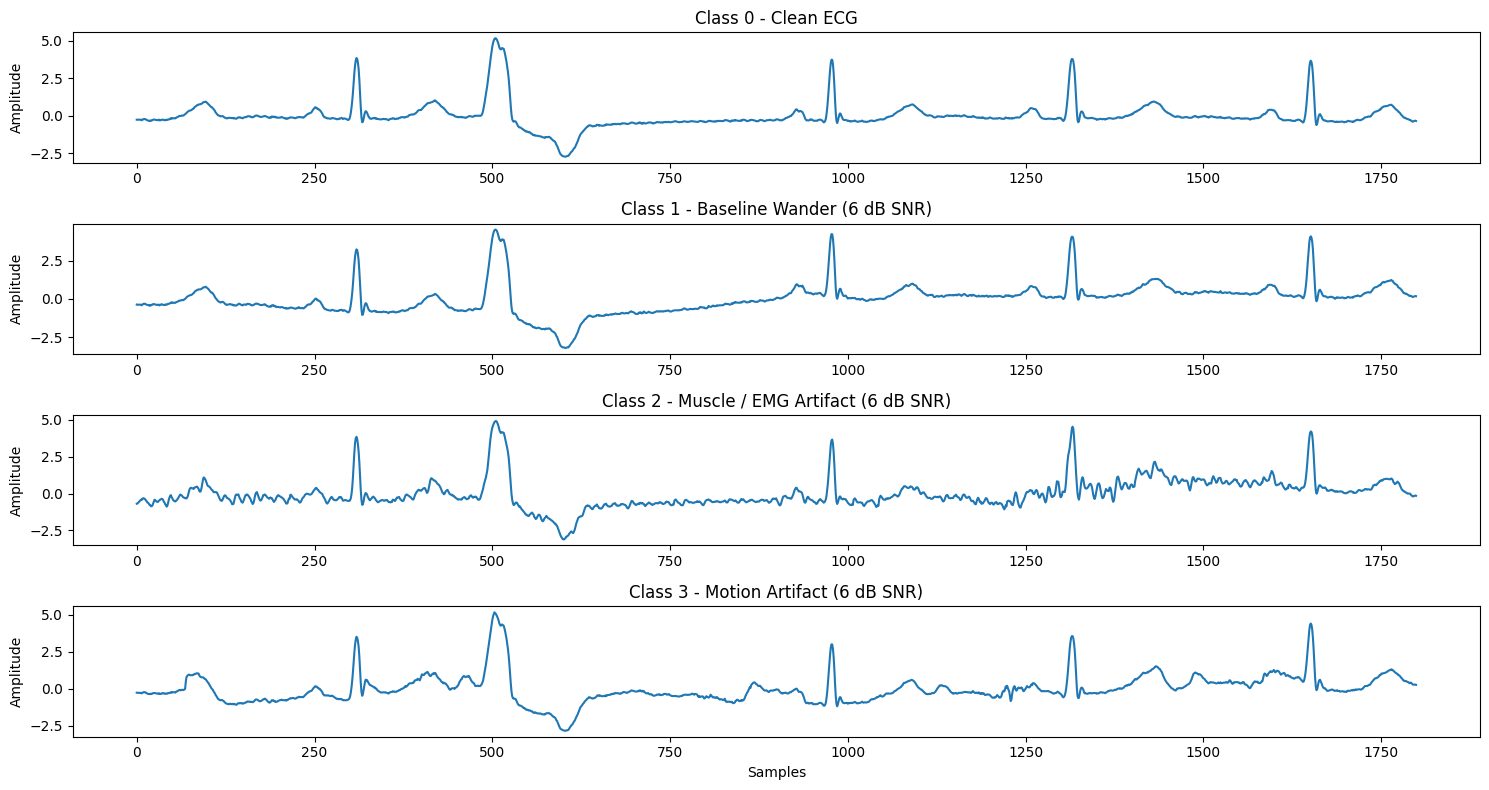

In [ ]:
plt.figure(figsize=(15, 8))
plt.subplot(4, 1, 1)
plt.plot(X_external[0])
plt.title("Class 0 - Clean ECG")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 2)
plt.plot(X_external[1])
plt.title("Class 1 - Baseline Wander (6 dB SNR)")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 3)
plt.plot(X_external[2])
plt.title("Class 2 - Muscle / EMG Artifact (6 dB SNR)")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 4)
plt.plot(X_external[3])
plt.title("Class 3 - Motion Artifact (6 dB SNR)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

13. Conventional Feature Function

In [ ]:
def conventional_features(x):
    features = [
        np.mean(x),
        np.std(x),
        np.var(x),
        np.min(x),
        np.max(x),
        np.ptp(x),
        np.sqrt(np.mean(x**2)),
        np.mean(np.abs(x)),
        np.median(x),
        np.percentile(x, 25),
        np.percentile(x, 75)
    ]
    return np.array(features)

14. Extracting Conventional Features from Record 119

In [ ]:
X_external_conventional = np.array([conventional_features(signal) for signal in X_external])
print("External conventional feature shape:", X_external_conventional.shape)

External conventional feature shape: (1444, 11)


15. Checking Nan and Infinite Values

In [ ]:
print("NaN values in external features:", np.isnan(X_external_conventional).sum())
print("Infinite values in external features:", np.isinf(X_external_conventional).sum())

NaN values in external features: 0
Infinite values in external features: 0


16. Uploading 3 Trained Models

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dt_conventional_model.pkl to dt_conventional_model.pkl


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving rf_conventional_model.pkl to rf_conventional_model.pkl


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving svm_conventional_model.pkl to svm_conventional_model.pkl


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'dt_conventional_model.pkl', 'rf_conventional_model.pkl', 'svm_conventional_model.pkl', 'sample_data']


In [ ]:
import joblib
dt_model_conventional = joblib.load("dt_conventional_model.pkl")
rf_model_conventional = joblib.load("rf_conventional_model.pkl")
svm_model_conventional = joblib.load("svm_conventional_model.pkl")
print("All conventional models loaded successfully.")

All conventional models loaded successfully.


17. Generating Predictions

In [ ]:
y_pred_dt_ext_conventional = dt_model_conventional.predict(X_external_conventional)
y_pred_rf_ext_conventional = rf_model_conventional.predict(X_external_conventional)
y_pred_svm_ext_conventional = svm_model_conventional.predict(X_external_conventional)
print("External conventional predictions completed successfully.")

External conventional predictions completed successfully.


18. Calculating External Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
dt_accuracy_ext_conventional = accuracy_score(
    y_external,
    y_pred_dt_ext_conventional
)
dt_precision_ext_conventional = precision_score(
    y_external,
    y_pred_dt_ext_conventional,
    average="weighted"
)
dt_recall_ext_conventional = recall_score(
    y_external,
    y_pred_dt_ext_conventional,
    average="weighted"
)
dt_f1_ext_conventional = f1_score(
    y_external,
    y_pred_dt_ext_conventional,
    average="weighted"
)
rf_accuracy_ext_conventional = accuracy_score(
    y_external,
    y_pred_rf_ext_conventional
)
rf_precision_ext_conventional = precision_score(
    y_external,
    y_pred_rf_ext_conventional,
    average="weighted"
)
rf_recall_ext_conventional = recall_score(
    y_external,
    y_pred_rf_ext_conventional,
    average="weighted"
)
rf_f1_ext_conventional = f1_score(
    y_external,
    y_pred_rf_ext_conventional,
    average="weighted"
)
svm_accuracy_ext_conventional = accuracy_score(
    y_external,
    y_pred_svm_ext_conventional
)
svm_precision_ext_conventional = precision_score(
    y_external,
    y_pred_svm_ext_conventional,
    average="weighted"
)
svm_recall_ext_conventional = recall_score(
    y_external,
    y_pred_svm_ext_conventional,
    average="weighted"
)
svm_f1_ext_conventional = f1_score(
    y_external,
    y_pred_svm_ext_conventional,
    average="weighted"
)
print("External Validation Results — Record 119 — Conventional Features")
print("---------------------------------------------------------------")
print(
    f"Decision Tree   | Accuracy: {dt_accuracy_ext_conventional:.4f} | "
    f"Precision: {dt_precision_ext_conventional:.4f} | "
    f"Recall: {dt_recall_ext_conventional:.4f} | "
    f"F1: {dt_f1_ext_conventional:.4f}"
)
print(
    f"Random Forest   | Accuracy: {rf_accuracy_ext_conventional:.4f} | "
    f"Precision: {rf_precision_ext_conventional:.4f} | "
    f"Recall: {rf_recall_ext_conventional:.4f} | "
    f"F1: {rf_f1_ext_conventional:.4f}"
)
print(
    f"SVM             | Accuracy: {svm_accuracy_ext_conventional:.4f} | "
    f"Precision: {svm_precision_ext_conventional:.4f} | "
    f"Recall: {svm_recall_ext_conventional:.4f} | "
    f"F1: {svm_f1_ext_conventional:.4f}"
)

External Validation Results — Record 119 — Conventional Features
---------------------------------------------------------------
Decision Tree   | Accuracy: 0.3511 | Precision: 0.3785 | Recall: 0.3511 | F1: 0.3509
Random Forest   | Accuracy: 0.3913 | Precision: 0.4639 | Recall: 0.3913 | F1: 0.3232
SVM             | Accuracy: 0.3186 | Precision: 0.5490 | Recall: 0.3186 | F1: 0.2386


 19. Classification Report

In [ ]:
from sklearn.metrics import classification_report
class_names = [
    "Clean ECG",
    "Baseline Wander",
    "EMG Artifact",
    "Motion Artifact"
]
print("===== Decision Tree — Conventional Features — Record 119 =====")
print(
    classification_report(
        y_external,
        y_pred_dt_ext_conventional,
        target_names=class_names
    )
)
print("===== Random Forest — Conventional Features — Record 119 =====")
print(
    classification_report(
        y_external,
        y_pred_rf_ext_conventional,
        target_names=class_names
    )
)
print("===== SVM — Conventional Features — Record 119 =====")
print(
    classification_report(
        y_external,
        y_pred_svm_ext_conventional,
        target_names=class_names
    )
)

===== Decision Tree — Conventional Features — Record 119 =====
                 precision    recall  f1-score   support

      Clean ECG       0.61      0.53      0.56       361
Baseline Wander       0.37      0.17      0.23       361
   EMG Artifact       0.30      0.38      0.34       361
Motion Artifact       0.23      0.34      0.27       361

       accuracy                           0.35      1444
      macro avg       0.38      0.35      0.35      1444
   weighted avg       0.38      0.35      0.35      1444

===== Random Forest — Conventional Features — Record 119 =====
                 precision    recall  f1-score   support

      Clean ECG       0.58      0.62      0.60       361
Baseline Wander       0.55      0.02      0.03       361
   EMG Artifact       0.42      0.15      0.22       361
Motion Artifact       0.31      0.78      0.44       361

       accuracy                           0.39      1444
      macro avg       0.46      0.39      0.32      1444
   weighted av

20. Confusion Matrices

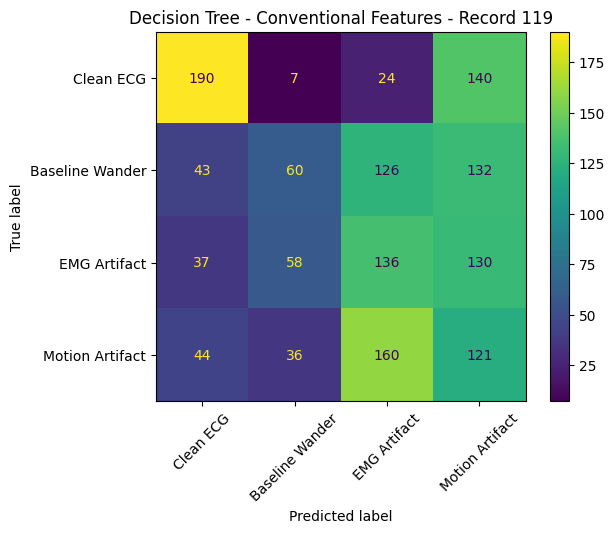

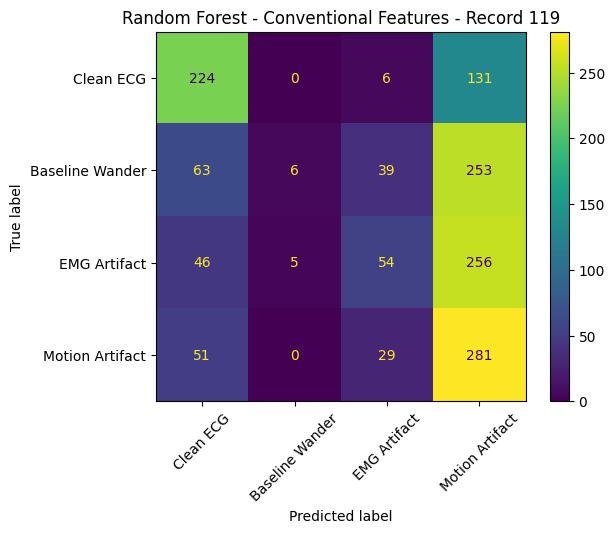

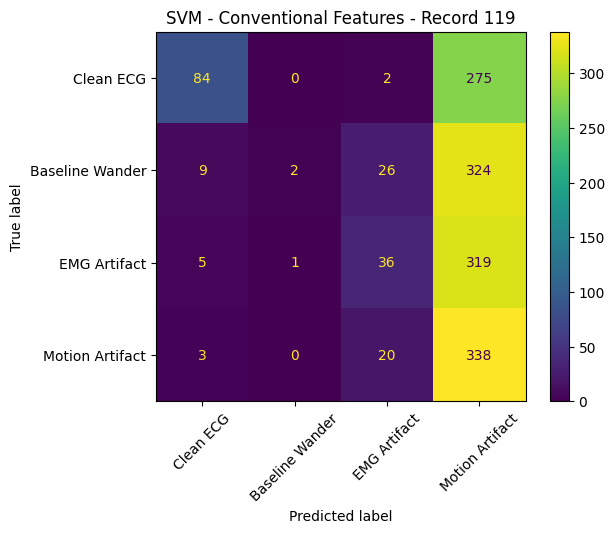

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
class_names = [
    "Clean ECG",
    "Baseline Wander",
    "EMG Artifact",
    "Motion Artifact"
]
ConfusionMatrixDisplay.from_predictions(
    y_external,
    y_pred_dt_ext_conventional,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("Decision Tree - Conventional Features - Record 119")
plt.show()
ConfusionMatrixDisplay.from_predictions(
    y_external,
    y_pred_rf_ext_conventional,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("Random Forest - Conventional Features - Record 119")
plt.show()
ConfusionMatrixDisplay.from_predictions(
    y_external,
    y_pred_svm_ext_conventional,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("SVM - Conventional Features - Record 119")
plt.show()